In [2]:
pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 23.1 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 3.8 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [3]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="your-api-key")
project = rf.workspace("roboflow-jvuqo").project("football-field-detection-f07vi")
version = project.version(18)
dataset = version.download("yolov8")
                

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 7.1 MB/s eta 0:00:00ta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 80.1 MB/s eta 0:00:00ta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 3.2 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to football-field-detection-18 in yolov8:: 100%|██████████| 639/639 [00:00<00:00, 7156.25it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [4]:
from pathlib import Path

SEARCH_ROOTS = [
    Path("/kaggle/input"),
    Path("/kaggle/working"),
]

found = {
    "weights": [],
    "video": [],
    "tracking": [],
    "dataset_yaml": [],
}

for root in SEARCH_ROOTS:
    if not root.exists():
        continue

    for path in root.rglob("*"):
        if not path.is_file():
            continue

        name = path.name.lower()
        full_path = str(path).lower()

        if name.endswith(".pt") and "best" in name:
            found["weights"].append(path)

        if name == "08fd33_4.mp4":
            found["video"].append(path)

        if name == "tracking_results1.pkl":
            found["tracking"].append(path)

        if name == "data.yaml" and "football" in full_path:
            found["dataset_yaml"].append(path)

# Print results
for asset, paths in found.items():
    print(f"\n{'=' * 20} {asset.upper()} {'=' * 20}")

    if paths:
        for path in paths:
            size_mb = path.stat().st_size / (1024 ** 2)
            print(f"{path}  ({size_mb:.2f} MB)")
    else:
        print("NOT FOUND")

print("\nFile discovery complete.")


==================== WEIGHTS ====================
/kaggle/input/datasets/anishnagargoje/footballviddeo/best (1).pt  (19.39 MB)
/kaggle/input/datasets/anishnagargoje/footballviddeo/best (3).pt  (133.59 MB)

==================== VIDEO ====================
/kaggle/input/datasets/anishnagargoje/footballviddeo/08fd33_4.mp4  (19.40 MB)

==================== TRACKING ====================
/kaggle/input/datasets/anishnagargoje/footballviddeo/tracking_results1.pkl  (1.13 MB)

==================== DATASET_YAML ====================
/kaggle/working/football-field-detection-18/data.yaml  (0.00 MB)

File discovery complete.


## training the pitch keypoint model

In [ ]:
# ============================================================
# TRAIN FOOTBALL PITCH KEYPOINT DETECTION MODEL
# Model: YOLOv8x-Pose
# Dataset: Football Field Detection v18 (32 keypoints)
# ============================================================

!pip install -q ultralytics

from ultralytics import YOLO
from pathlib import Path
import shutil

# Dataset configuration
DATA_YAML = "/kaggle/working/football-field-detection-18/data.yaml"

# Training output directory
OUTPUT_DIR = Path("/kaggle/working/FootballVision/phase4_training")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load pretrained YOLOv8x pose model
model = YOLO("yolov8x-pose.pt")

# Train
results = model.train(
    data=DATA_YAML,
    epochs=100,
    imgsz=640,
    batch=4,
    device=0,
    workers=2,
    patience=20,
    project=str(OUTPUT_DIR),
    name="pitch_keypoint_yolov8x_pose",
    save=True,
    plots=True,
    seed=42
)

# Save the best checkpoint under a stable filename
trained_weights = (
    OUTPUT_DIR
    / "pitch_keypoint_yolov8x_pose"
    / "weights"
    / "best.pt"
)

final_weights = OUTPUT_DIR / "best_pitch_keypoint.pt"

if trained_weights.exists():
    shutil.copy2(trained_weights, final_weights)
    print(f"Training complete. Best weights saved to: {final_weights}")
else:
    print(f"Training finished, but locate the best checkpoint in: {OUTPUT_DIR}")

## load the pitch key point model

In [5]:
from ultralytics import YOLO

model = YOLO(
    "/kaggle/input/datasets/anishnagargoje/footballviddeo/best (3).pt"
)

## testing the model on images

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

A — Original aspect ratio, imgsz=960
Pitch confidence: 0.937
Keypoint shape: (32, 3)
Keypoints >= 0.5: 14/32
Predicted box [x1, y1, x2, y2]: [0.0, 276.0, 1280.0, 957.0]

A — Original frame with predictions


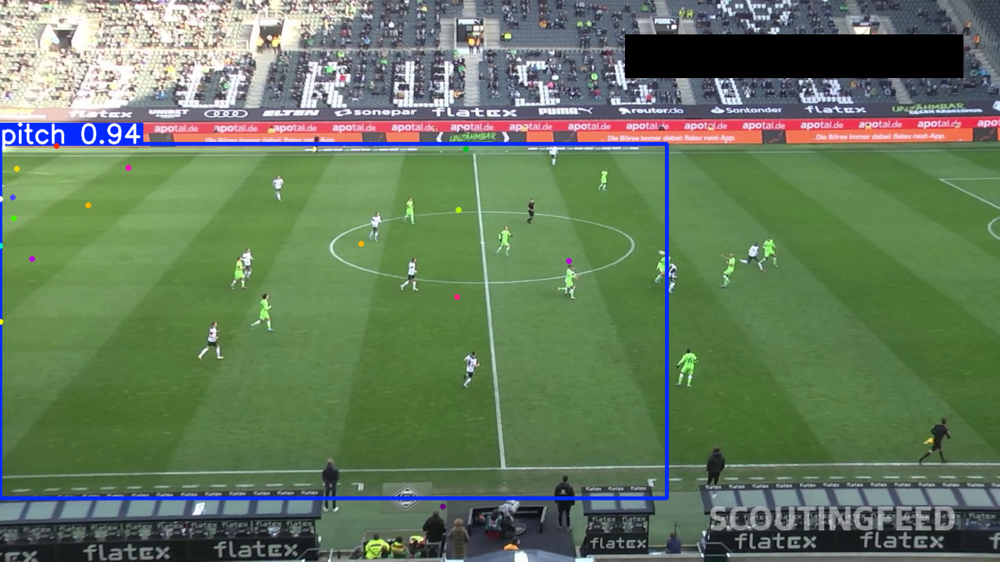

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.

B — Square-stretched input, imgsz=640
Pitch confidence: 0.951
Keypoint shape: (32, 3)
Keypoints >= 0.5: 8/32
Predicted box [x1, y1, x2, y2]: [1.0, 159.5, 640.0, 545.0]

B — Square-stretched input, mapped back to the video shape


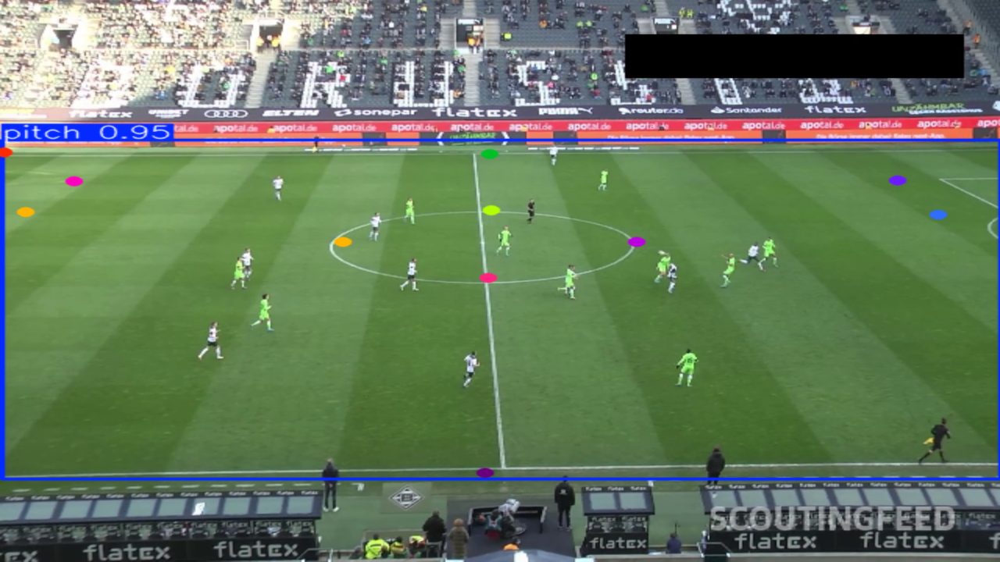

In [8]:
from pathlib import Path
import gc
import cv2
import torch
from ultralytics import YOLO
from PIL import Image as PILImage
from IPython.display import display

WEIGHTS = Path(
    "/kaggle/input/datasets/anishnagargoje/"
    "footballviddeo/best (3).pt"
)

VIDEO_PATH = Path(
    "/kaggle/input/datasets/anishnagargoje/"
    "footballviddeo/08fd33_4.mp4"
)

assert WEIGHTS.exists(), f"Missing weights: {WEIGHTS}"
assert VIDEO_PATH.exists(), f"Missing video: {VIDEO_PATH}"
assert torch.cuda.is_available(), "Enable Kaggle GPU first."

model = YOLO(str(WEIGHTS))

# Read the same original video frame for both tests
cap = cv2.VideoCapture(str(VIDEO_PATH))
cap.set(cv2.CAP_PROP_POS_FRAMES, 375)
ok, frame = cap.read()
cap.release()

assert ok, "Could not read frame 375."

H, W = frame.shape[:2]


def summarize_result(result, name):
    print(f"\n{name}")

    if len(result.boxes) == 0 or result.keypoints is None:
        print("No pitch/keypoint detection.")
        return

    box = result.boxes.xyxy[0].cpu().numpy()
    box_conf = float(result.boxes.conf[0].item())
    points = result.keypoints.data[0].cpu().numpy()

    print(f"Pitch confidence: {box_conf:.3f}")
    print(f"Keypoint shape: {points.shape}")
    print(f"Keypoints >= 0.5: {(points[:, 2] >= 0.5).sum()}/32")
    print("Predicted box [x1, y1, x2, y2]:",
          [round(float(v), 1) for v in box])


# ------------------------------------------------
# A — Original 16:9 frame, normal YOLO preprocessing
# ------------------------------------------------
result_normal = model.predict(
    source=frame,
    imgsz=960,
    conf=0.05,
    max_det=1,
    device=0,
    half=True,
    verbose=False
)[0]

summarize_result(result_normal, "A — Original aspect ratio, imgsz=960")

normal_vis = result_normal.plot()
normal_vis = cv2.resize(normal_vis, (1280, 720))

del result_normal
gc.collect()
torch.cuda.empty_cache()

print("\nA — Original frame with predictions")
display(PILImage.fromarray(cv2.cvtColor(normal_vis, cv2.COLOR_BGR2RGB)))


# ------------------------------------------------
# B — Stretch frame to square before inference
# ------------------------------------------------
square_frame = cv2.resize(
    frame,
    (640, 640),
    interpolation=cv2.INTER_LINEAR
)

result_square = model.predict(
    source=square_frame,
    imgsz=640,
    conf=0.05,
    max_det=1,
    device=0,
    half=True,
    verbose=False
)[0]

summarize_result(
    result_square,
    "B — Square-stretched input, imgsz=640"
)

# Plot on the square image, then stretch the annotated image
# back to the original frame dimensions for visual comparison.
square_vis = result_square.plot()
square_vis = cv2.resize(square_vis, (W, H))
square_vis = cv2.resize(square_vis, (1280, 720))

del result_square, square_frame
gc.collect()
torch.cuda.empty_cache()

print("\nB — Square-stretched input, mapped back to the video shape")
display(PILImage.fromarray(cv2.cvtColor(square_vis, cv2.COLOR_BGR2RGB)))

Original video dimensions: 1920 x 1080
Pitch confidence: 0.951
Keypoints >= 0.5: 8/32

ID     X-original   Y-original   Confidence
01          8.0        292.9     0.334
02          0.0        338.2     0.101
03          0.0        381.2     0.037
04          0.0        464.9     0.005
05          0.0        549.1     0.002
06          0.0        446.6     0.001
07          0.0        393.4     0.103
08          0.0        453.6     0.010
09          0.0        432.4     0.099
10        143.6        348.6     0.722
11         50.3        406.6     0.473
12          0.0        492.8     0.113
13          0.0        600.6     0.014
14        939.5        295.7     0.989
15        943.6        403.5     0.991
16        936.2        533.5     0.993
17        931.9        908.4     0.751
18       1722.2        345.9     0.621
19       1800.3        411.8     0.415
20       1920.0        500.3     0.091
21       1920.0        575.2     0.011
22       1920.0        452.7     0.069
23       19

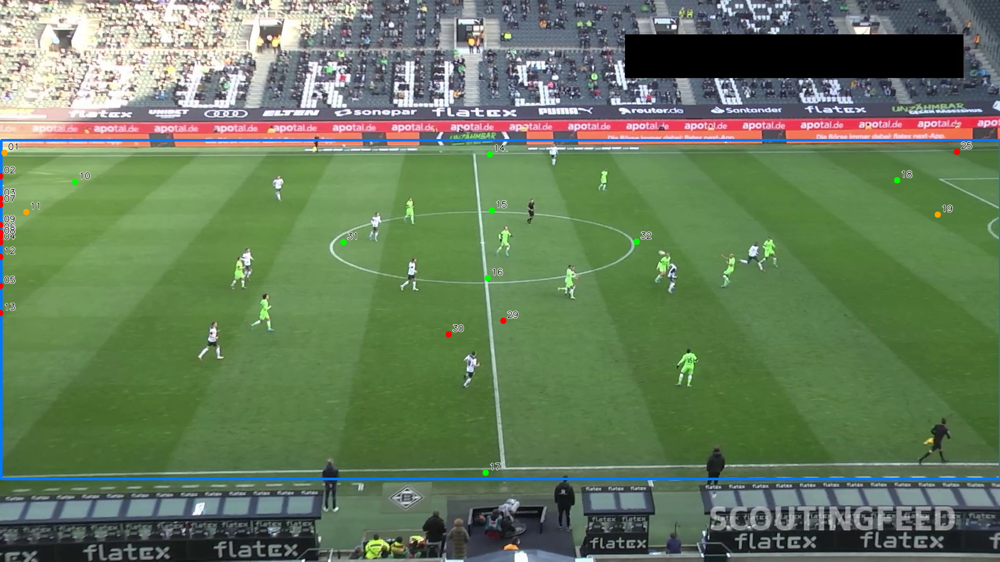

In [9]:
from pathlib import Path
import cv2
import numpy as np
from ultralytics import YOLO
from PIL import Image as PILImage
from IPython.display import display

WEIGHTS = Path(
    "/kaggle/input/datasets/anishnagargoje/"
    "footballviddeo/best (3).pt"
)
VIDEO_PATH = Path(
    "/kaggle/input/datasets/anishnagargoje/"
    "footballviddeo/08fd33_4.mp4"
)

model = YOLO(str(WEIGHTS))

# Read frame 375
cap = cv2.VideoCapture(str(VIDEO_PATH))
cap.set(cv2.CAP_PROP_POS_FRAMES, 375)
ok, frame = cap.read()
cap.release()

assert ok, "Could not read frame 375."

H, W = frame.shape[:2]

# Match the square-image shape used by the dataset
square_frame = cv2.resize(
    frame, (640, 640), interpolation=cv2.INTER_LINEAR
)

result = model.predict(
    source=square_frame,
    imgsz=640,
    conf=0.05,
    max_det=1,
    device=0,
    verbose=False
)[0]

assert len(result.boxes) > 0 and result.keypoints is not None, (
    "No pitch detection. Stop here."
)

points = result.keypoints.data[0].cpu().numpy()
box = result.boxes.xyxy[0].cpu().numpy()
box_conf = float(result.boxes.conf[0].item())

# Convert model coordinates from the stretched square back
# into the original 1920 x 1080 video coordinate system.
points_original = points.copy()
points_original[:, 0] *= W / 640
points_original[:, 1] *= H / 640

box_original = box.copy()
box_original[[0, 2]] *= W / 640
box_original[[1, 3]] *= H / 640

print(f"Original video dimensions: {W} x {H}")
print(f"Pitch confidence: {box_conf:.3f}")
print(f"Keypoints >= 0.5: {(points[:, 2] >= 0.5).sum()}/32")
print("\nID     X-original   Y-original   Confidence")

for i, (x, y, conf) in enumerate(points_original, start=1):
    print(f"{i:02d}     {x:8.1f}     {y:8.1f}     {conf:.3f}")

# Draw the transformed predictions on the original video frame
vis = frame.copy()

x1, y1, x2, y2 = np.round(box_original).astype(int)
cv2.rectangle(vis, (x1, y1), (x2, y2), (255, 120, 0), 3)

for i, (x, y, conf) in enumerate(points_original, start=1):
    if not (0 <= x < W and 0 <= y < H):
        continue

    if conf >= 0.5:
        color = (0, 255, 0)
    elif conf >= 0.25:
        color = (0, 165, 255)
    else:
        color = (0, 0, 255)

    px, py = int(round(x)), int(round(y))
    cv2.circle(vis, (px, py), 6, color, -1)
    cv2.putText(
        vis, f"{i:02d}", (px + 7, py - 6),
        cv2.FONT_HERSHEY_SIMPLEX, 0.55,
        (255, 255, 255), 2, cv2.LINE_AA
    )
    cv2.putText(
        vis, f"{i:02d}", (px + 7, py - 6),
        cv2.FONT_HERSHEY_SIMPLEX, 0.55,
        (0, 0, 0), 1, cv2.LINE_AA
    )

print("\nGreen: confidence >= 0.5 | Orange: 0.25–0.5 | Red: < 0.25")
display(PILImage.fromarray(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)))

Video frame: 1920 x 1080

Candidate landmark IDs: [10, 14, 15, 16, 17, 18, 31, 32]
Candidates: 8

RANSAC inliers: 8/8

Candidate correspondence check:
ID 10: confidence=0.722, error=0.26 m, INLIER
ID 14: confidence=0.989, error=0.39 m, INLIER
ID 15: confidence=0.991, error=0.08 m, INLIER
ID 16: confidence=0.993, error=0.32 m, INLIER
ID 17: confidence=0.751, error=0.14 m, INLIER
ID 18: confidence=0.621, error=0.32 m, INLIER
ID 31: confidence=0.990, error=0.84 m, INLIER
ID 32: confidence=0.989, error=0.96 m, INLIER

Core landmark inliers: {14: True, 15: True, 16: True, 17: True, 31: True, 32: True}

Overlay legend: YELLOW = projected field markings; GREEN = RANSAC inlier; RED = RANSAC outlier.


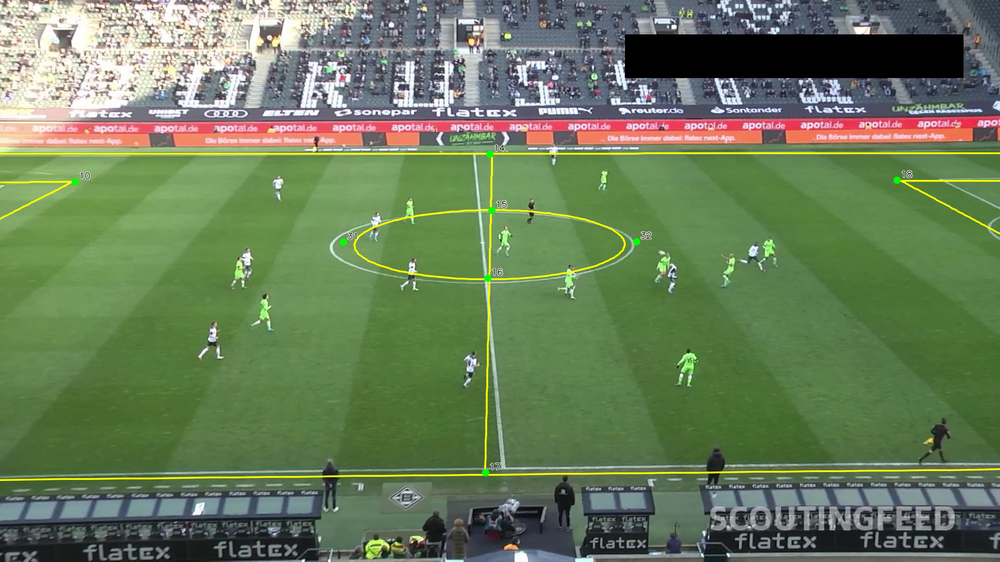

In [10]:
from pathlib import Path
import cv2
import numpy as np
import torch
from ultralytics import YOLO
from PIL import Image as PILImage
from IPython.display import display

# --------------------------------------------------
# 1. Paths and model
# --------------------------------------------------

WEIGHTS = Path(
    "/kaggle/input/datasets/anishnagargoje/"
    "footballviddeo/best (3).pt"
)
VIDEO_PATH = Path(
    "/kaggle/input/datasets/anishnagargoje/"
    "footballviddeo/08fd33_4.mp4"
)

assert WEIGHTS.exists(), f"Weights not found: {WEIGHTS}"
assert VIDEO_PATH.exists(), f"Video not found: {VIDEO_PATH}"
assert torch.cuda.is_available(), "Enable the Kaggle GPU."

model = YOLO(str(WEIGHTS))

# Read frame 375
cap = cv2.VideoCapture(str(VIDEO_PATH))
cap.set(cv2.CAP_PROP_POS_FRAMES, 375)
ok, frame = cap.read()
cap.release()

assert ok, "Could not read frame 375."

H_img, W_img = frame.shape[:2]
print(f"Video frame: {W_img} x {H_img}")


# --------------------------------------------------
# 2. Predict landmarks using square-stretched input
# --------------------------------------------------

square_frame = cv2.resize(frame, (640, 640))

result = model.predict(
    source=square_frame,
    imgsz=640,
    conf=0.05,
    max_det=1,
    device=0,
    verbose=False
)[0]

assert len(result.boxes) > 0 and result.keypoints is not None, (
    "No pitch/keypoint prediction. Cannot estimate homography."
)

predicted = result.keypoints.data[0].cpu().numpy().copy()

# Restore keypoints to the original video's pixel coordinates.
predicted[:, 0] *= W_img / 640
predicted[:, 1] *= H_img / 640

source_all = predicted[:, :2]
confidence = predicted[:, 2]


# --------------------------------------------------
# 3. Define the 32 target pitch vertices in metres
# --------------------------------------------------

# Assumed field dimensions: 105 m x 68 m.
L = 105.0
W = 68.0

penalty_width = 40.32
goal_width = 18.32
penalty_depth = 16.5
goal_depth = 5.5
centre_radius = 9.15
penalty_spot = 11.0

y_pen_top = (W - penalty_width) / 2
y_goal_top = (W - goal_width) / 2
y_goal_bottom = (W + goal_width) / 2
y_pen_bottom = (W + penalty_width) / 2

# IMPORTANT: preserve the dataset's original index ordering.
pitch_vertices = np.array([
    [0, 0],                         # 01
    [0, y_pen_top],                 # 02
    [0, y_goal_top],                # 03
    [0, y_goal_bottom],             # 04
    [0, y_pen_bottom],              # 05
    [0, W],                         # 06
    [goal_depth, y_goal_top],       # 07
    [goal_depth, y_goal_bottom],    # 08
    [penalty_spot, W / 2],          # 09
    [penalty_depth, y_pen_top],     # 10
    [penalty_depth, y_goal_top],    # 11
    [penalty_depth, y_goal_bottom], # 12
    [penalty_depth, y_pen_bottom],  # 13
    [L / 2, 0],                     # 14
    [L / 2, W / 2 - centre_radius], # 15
    [L / 2, W / 2 + centre_radius], # 16
    [L / 2, W],                     # 17
    [L - penalty_depth, y_pen_top], # 18
    [L - penalty_depth, y_goal_top],# 19
    [L - penalty_depth, y_goal_bottom], # 20
    [L - penalty_depth, y_pen_bottom],  # 21
    [L - penalty_spot, W / 2],      # 22
    [L - goal_depth, y_goal_top],   # 23
    [L - goal_depth, y_goal_bottom],# 24
    [L, 0],                         # 25
    [L, y_pen_top],                 # 26
    [L, y_goal_top],                # 27
    [L, y_goal_bottom],              # 28
    [L, y_pen_bottom],               # 29
    [L, W],                         # 30
    [L / 2 - centre_radius, W / 2], # 31
    [L / 2 + centre_radius, W / 2], # 32
], dtype=np.float32)

assert pitch_vertices.shape == (32, 2)


# --------------------------------------------------
# 4. Select credible candidate landmarks
# --------------------------------------------------

# Ignore low-confidence predictions and points at image edges.
valid = (
    (confidence >= 0.5)
    & (source_all[:, 0] > 1)
    & (source_all[:, 0] < W_img - 1)
    & (source_all[:, 1] > 1)
    & (source_all[:, 1] < H_img - 1)
)

candidate_indices = np.flatnonzero(valid)
source = source_all[valid].astype(np.float32)
target = pitch_vertices[valid].astype(np.float32)

print("\nCandidate landmark IDs:",
      [int(i + 1) for i in candidate_indices])
print("Candidates:", len(source))

if len(source) < 4:
    raise RuntimeError(
        "Fewer than four usable landmarks. "
        "We need more reliable predictions before calibration."
    )


# --------------------------------------------------
# 5. Fit a RANSAC homography
# --------------------------------------------------

H_matrix, inlier_mask = cv2.findHomography(
    source,
    target,
    method=cv2.RANSAC,
    ransacReprojThreshold=2.5  # metres in target coordinates
)

if H_matrix is None or inlier_mask is None:
    raise RuntimeError(
        "Homography estimation failed. Do not use player coordinates yet."
    )

inliers = inlier_mask.ravel().astype(bool)
inlier_count = int(inliers.sum())

projected = cv2.perspectiveTransform(
    source.reshape(-1, 1, 2), H_matrix
).reshape(-1, 2)

errors = np.linalg.norm(projected - target, axis=1)

print(f"\nRANSAC inliers: {inlier_count}/{len(source)}")
print("\nCandidate correspondence check:")

for j, index in enumerate(candidate_indices):
    status = "INLIER" if inliers[j] else "OUTLIER"
    print(
        f"ID {index + 1:02d}: confidence={confidence[index]:.3f}, "
        f"error={errors[j]:.2f} m, {status}"
    )

# Verify the landmarks central to this calibration.
core_ids = {14, 15, 16, 17, 31, 32}

core_results = {
    int(index + 1): bool(inliers[j])
    for j, index in enumerate(candidate_indices)
    if int(index + 1) in core_ids
}

print("\nCore landmark inliers:", core_results)

if inlier_count < 5:
    print(
        "\nWARNING: Too few inliers for a trustworthy calibration. "
        "Treat this homography as a failed diagnostic."
    )


# --------------------------------------------------
# 6. Draw projected pitch markings on the video frame
# --------------------------------------------------

# H maps video pixels -> pitch metres.
# Its inverse maps pitch metres -> video pixels.
H_inverse = np.linalg.inv(H_matrix)
overlay = frame.copy()

def draw_pitch_line(points_metres, color=(0, 255, 255), thickness=2):
    """Project a pitch polyline back onto the video frame."""
    points_metres = np.asarray(
        points_metres, dtype=np.float32
    ).reshape(-1, 1, 2)

    image_points = cv2.perspectiveTransform(
        points_metres, H_inverse
    ).reshape(-1, 2)

    max_dim = max(W_img, H_img)

    for a, b in zip(image_points[:-1], image_points[1:]):
        if not (np.isfinite(a).all() and np.isfinite(b).all()):
            continue

        # Avoid enormous coordinates and jumps near projective infinity.
        if max(np.abs(a).max(), np.abs(b).max()) > 4 * max_dim:
            continue
        if np.linalg.norm(a - b) > max_dim * 0.25:
            continue

        p1 = tuple(np.round(a).astype(int))
        p2 = tuple(np.round(b).astype(int))

        visible, clipped_p1, clipped_p2 = cv2.clipLine(
            (0, 0, W_img, H_img), p1, p2
        )

        if visible:
            cv2.line(
                overlay, clipped_p1, clipped_p2,
                color, thickness, cv2.LINE_AA
            )

def straight_line(start, end, n=100):
    start = np.asarray(start, dtype=np.float32)
    end = np.asarray(end, dtype=np.float32)
    t = np.linspace(0, 1, n, dtype=np.float32)[:, None]
    return start + t * (end - start)

# Pitch boundaries and halfway line
draw_pitch_line(straight_line((0, 0), (L, 0)))
draw_pitch_line(straight_line((0, W), (L, W)))
draw_pitch_line(straight_line((0, 0), (0, W)))
draw_pitch_line(straight_line((L, 0), (L, W)))
draw_pitch_line(straight_line((L / 2, 0), (L / 2, W)))

# Centre circle
angles = np.linspace(0, 2 * np.pi, 160)
circle = np.column_stack([
    L / 2 + centre_radius * np.cos(angles),
    W / 2 + centre_radius * np.sin(angles),
]).astype(np.float32)
draw_pitch_line(circle)

# Penalty and goal boxes on both ends
for x1, x2, box_width in [
    (0, penalty_depth, penalty_width),
    (L - penalty_depth, L, penalty_width),
    (0, goal_depth, goal_width),
    (L - goal_depth, L, goal_width),
]:
    y_top = (W - box_width) / 2
    y_bottom = (W + box_width) / 2

    draw_pitch_line(straight_line((x1, y_top), (x2, y_top)))
    draw_pitch_line(straight_line((x1, y_bottom), (x2, y_bottom)))
    draw_pitch_line(straight_line((x1, y_top), (x1, y_bottom)))
    draw_pitch_line(straight_line((x2, y_top), (x2, y_bottom)))

# Mark accepted and rejected candidate landmarks on the frame.
for j, index in enumerate(candidate_indices):
    x, y = np.round(source[j]).astype(int)
    color = (0, 255, 0) if inliers[j] else (0, 0, 255)

    cv2.circle(overlay, (x, y), 7, color, -1)
    cv2.putText(
        overlay, str(index + 1), (x + 7, y - 6),
        cv2.FONT_HERSHEY_SIMPLEX, 0.55,
        (255, 255, 255), 2, cv2.LINE_AA
    )
    cv2.putText(
        overlay, str(index + 1), (x + 7, y - 6),
        cv2.FONT_HERSHEY_SIMPLEX, 0.55,
        (0, 0, 0), 1, cv2.LINE_AA
    )

print("\nOverlay legend: YELLOW = projected field markings; "
      "GREEN = RANSAC inlier; RED = RANSAC outlier.")
display(PILImage.fromarray(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)))

Frame dimensions: 1920 x 1080
Loaded trained pitch-keypoint model.
Pitch confidence: 0.951

Selected landmark candidates:
ID 14: pixel=(939.5, 295.7), confidence=0.989
ID 15: pixel=(943.6, 403.5), confidence=0.991
ID 16: pixel=(936.2, 533.5), confidence=0.993
ID 17: pixel=(931.9, 908.4), confidence=0.751
ID 31: pixel=(658.9, 464.6), confidence=0.990
ID 32: pixel=(1222.3, 464.0), confidence=0.989

Usable landmarks: 6/6

RANSAC inliers: 6/6
Correspondence errors:
ID 14: 0.07 m, INLIER
ID 15: 0.21 m, INLIER
ID 16: 0.38 m, INLIER
ID 17: 0.05 m, INLIER
ID 31: 0.24 m, INLIER
ID 32: 0.24 m, INLIER

Yellow = projected halfway line and centre circle
Green = RANSAC inlier; red = RANSAC outlier


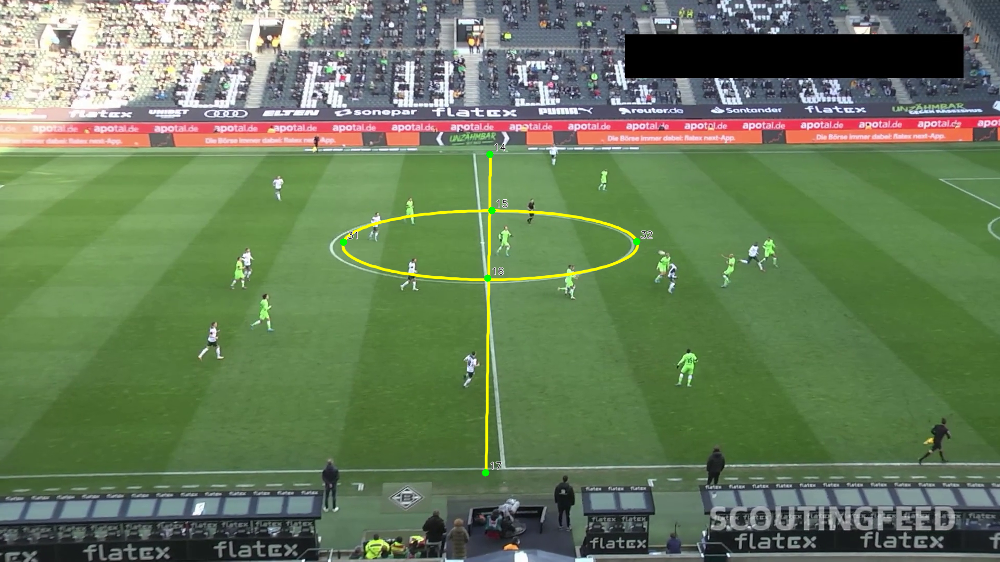

In [11]:
from pathlib import Path

import cv2
import numpy as np
import torch
from ultralytics import YOLO
from PIL import Image as PILImage
from IPython.display import display


# =========================================================
# 1. LOAD CHECKPOINT AND VIDEO
# =========================================================

WEIGHTS = Path(
    "/kaggle/input/datasets/anishnagargoje/"
    "footballviddeo/best (3).pt"
)

VIDEO_PATH = Path(
    "/kaggle/input/datasets/anishnagargoje/"
    "footballviddeo/08fd33_4.mp4"
)

assert WEIGHTS.exists(), f"Checkpoint not found: {WEIGHTS}"
assert VIDEO_PATH.exists(), f"Video not found: {VIDEO_PATH}"
assert torch.cuda.is_available(), "Enable the Kaggle GPU first."

model = YOLO(str(WEIGHTS))

cap = cv2.VideoCapture(str(VIDEO_PATH))
cap.set(cv2.CAP_PROP_POS_FRAMES, 375)
ok, frame = cap.read()
cap.release()

assert ok, "Could not read frame 375."

H_img, W_img = frame.shape[:2]

print(f"Frame dimensions: {W_img} x {H_img}")
print("Loaded trained pitch-keypoint model.")


# =========================================================
# 2. RUN INFERENCE USING SQUARE-STRETCHED INPUT
# =========================================================

# This matches the square preprocessing we tested previously.
square_frame = cv2.resize(
    frame, (640, 640), interpolation=cv2.INTER_LINEAR
)

result = model.predict(
    source=square_frame,
    imgsz=640,
    conf=0.05,
    max_det=1,
    device=0,
    verbose=False,
)[0]

assert len(result.boxes) > 0, "No pitch detected."
assert result.keypoints is not None, "No keypoints returned."

pred = result.keypoints.data[0].cpu().numpy()

assert pred.shape == (32, 3), (
    f"Expected (32, 3) keypoints, got {pred.shape}"
)

# Convert square-input coordinates back to original video pixels.
image_points_all = pred[:, :2].copy()
image_points_all[:, 0] *= W_img / 640.0
image_points_all[:, 1] *= H_img / 640.0
confidence = pred[:, 2]

print("Pitch confidence:", round(float(result.boxes.conf[0].item()), 3))


# =========================================================
# 3. DEFINE THE REFERENCE PITCH IN METRES
# =========================================================

# Assumed real pitch dimensions.
# Change these if the actual pitch dimensions are known.
LENGTH = 105.0
WIDTH = 68.0

PENALTY_LENGTH = 16.5
PENALTY_WIDTH = 40.32

GOAL_AREA_LENGTH = 5.5
GOAL_AREA_WIDTH = 18.32

CENTER_CIRCLE_RADIUS = 9.15
PENALTY_SPOT_DISTANCE = 11.0

# These 32 vertices follow the Roboflow SoccerPitchConfiguration
# order: vertex 1 corresponds to keypoint ID 01, etc.
y_pen_top = (WIDTH - PENALTY_WIDTH) / 2
y_goal_top = (WIDTH - GOAL_AREA_WIDTH) / 2
y_goal_bottom = (WIDTH + GOAL_AREA_WIDTH) / 2
y_pen_bottom = (WIDTH + PENALTY_WIDTH) / 2

pitch_vertices = np.array([
    (0, 0),                                      # 01
    (0, y_pen_top),                              # 02
    (0, y_goal_top),                             # 03
    (0, y_goal_bottom),                          # 04
    (0, y_pen_bottom),                           # 05
    (0, WIDTH),                                  # 06
    (GOAL_AREA_LENGTH, y_goal_top),              # 07
    (GOAL_AREA_LENGTH, y_goal_bottom),           # 08
    (PENALTY_SPOT_DISTANCE, WIDTH / 2),          # 09
    (PENALTY_LENGTH, y_pen_top),                 # 10
    (PENALTY_LENGTH, y_goal_top),                # 11
    (PENALTY_LENGTH, y_goal_bottom),             # 12
    (PENALTY_LENGTH, y_pen_bottom),              # 13
    (LENGTH / 2, 0),                             # 14
    (LENGTH / 2, WIDTH / 2 - CENTER_CIRCLE_RADIUS),  # 15
    (LENGTH / 2, WIDTH / 2 + CENTER_CIRCLE_RADIUS),  # 16
    (LENGTH / 2, WIDTH),                         # 17
    (LENGTH - PENALTY_LENGTH, y_pen_top),        # 18
    (LENGTH - PENALTY_LENGTH, y_goal_top),       # 19
    (LENGTH - PENALTY_LENGTH, y_goal_bottom),    # 20
    (LENGTH - PENALTY_LENGTH, y_pen_bottom),     # 21
    (LENGTH - PENALTY_SPOT_DISTANCE, WIDTH / 2), # 22
    (LENGTH - GOAL_AREA_LENGTH, y_goal_top),     # 23
    (LENGTH - GOAL_AREA_LENGTH, y_goal_bottom),  # 24
    (LENGTH, 0),                                 # 25
    (LENGTH, y_pen_top),                         # 26
    (LENGTH, y_goal_top),                        # 27
    (LENGTH, y_goal_bottom),                     # 28
    (LENGTH, y_pen_bottom),                      # 29
    (LENGTH, WIDTH),                             # 30
    (LENGTH / 2 - CENTER_CIRCLE_RADIUS, WIDTH / 2),  # 31
    (LENGTH / 2 + CENTER_CIRCLE_RADIUS, WIDTH / 2),  # 32
], dtype=np.float32)

assert pitch_vertices.shape == (32, 2)


# =========================================================
# 4. SELECT ONLY THE SIX CENTRAL LANDMARKS
# =========================================================

# These are the landmarks we visually inspected:
# 14, 15, 16, 17 = halfway line endpoints and circle intersections
# 31, 32 = left and right centre-circle intersections
#
# We deliberately EXCLUDE points 10 and 18 because their positions
# in this frame do not appear to match the visible field markings,
# despite their high model confidence.

selected_ids = [14, 15, 16, 17, 31, 32]
selected_indices = np.array(selected_ids) - 1

source_candidates = image_points_all[selected_indices]
target_candidates = pitch_vertices[selected_indices]
selected_confidences = confidence[selected_indices]

print("\nSelected landmark candidates:")
for point_id, xy, conf in zip(
    selected_ids, source_candidates, selected_confidences
):
    print(
        f"ID {point_id:02d}: "
        f"pixel=({xy[0]:.1f}, {xy[1]:.1f}), "
        f"confidence={conf:.3f}"
    )

# Require these selected points to be reasonably confident and in frame.
inside = (
    (source_candidates[:, 0] >= 0)
    & (source_candidates[:, 0] < W_img)
    & (source_candidates[:, 1] >= 0)
    & (source_candidates[:, 1] < H_img)
)

usable = (selected_confidences >= 0.5) & inside

used_ids = np.array(selected_ids)[usable]
source = source_candidates[usable].astype(np.float32)
target = target_candidates[usable].astype(np.float32)

print(f"\nUsable landmarks: {len(source)}/{len(selected_ids)}")

if len(source) < 4:
    raise RuntimeError(
        "Fewer than four usable landmarks. "
        "We cannot estimate a homography reliably."
    )


# =========================================================
# 5. ESTIMATE IMAGE-TO-PITCH HOMOGRAPHY
# =========================================================

# H maps image pixels -> pitch metres.
# RANSAC rejects inconsistent correspondences.
H_matrix, inlier_mask = cv2.findHomography(
    source,
    target,
    method=cv2.RANSAC,
    ransacReprojThreshold=2.0,  # metres in target coordinates
)

if H_matrix is None or inlier_mask is None:
    raise RuntimeError("Homography estimation failed.")

inliers = inlier_mask.ravel().astype(bool)

# Transform the source points into pitch coordinates and measure errors.
projected_pitch = cv2.perspectiveTransform(
    source.reshape(-1, 1, 2),
    H_matrix,
).reshape(-1, 2)

errors_m = np.linalg.norm(projected_pitch - target, axis=1)

print(f"\nRANSAC inliers: {int(inliers.sum())}/{len(source)}")
print("Correspondence errors:")
for point_id, error, is_inlier in zip(used_ids, errors_m, inliers):
    print(
        f"ID {point_id:02d}: "
        f"{error:.2f} m, "
        f"{'INLIER' if is_inlier else 'OUTLIER'}"
    )

if int(inliers.sum()) < 4:
    raise RuntimeError(
        "Too few inliers. Do not use this homography."
    )

# Invert it to project pitch locations back into the image.
H_inverse = np.linalg.inv(H_matrix)


# =========================================================
# 6. OVERLAY THE HALF-WAY LINE AND CENTRE CIRCLE
# =========================================================

overlay = frame.copy()

def draw_projected_polyline(pitch_xy, color=(0, 255, 255), thickness=3):
    """Project a line defined in pitch metres back onto the video."""
    pitch_xy = np.asarray(pitch_xy, dtype=np.float32).reshape(-1, 1, 2)

    image_xy = cv2.perspectiveTransform(
        pitch_xy, H_inverse
    ).reshape(-1, 2)

    for a, b in zip(image_xy[:-1], image_xy[1:]):
        if not (np.isfinite(a).all() and np.isfinite(b).all()):
            continue

        # Ignore numerically unstable points far outside the image.
        if max(np.abs(a).max(), np.abs(b).max()) > 4 * max(W_img, H_img):
            continue

        p1 = tuple(np.round(a).astype(int))
        p2 = tuple(np.round(b).astype(int))

        visible, clipped_p1, clipped_p2 = cv2.clipLine(
            (0, 0, W_img, H_img), p1, p2
        )

        if visible:
            cv2.line(
                overlay,
                clipped_p1,
                clipped_p2,
                color,
                thickness,
                cv2.LINE_AA,
            )

# Halfway line
halfway_line = np.column_stack([
    np.full(150, LENGTH / 2, dtype=np.float32),
    np.linspace(0, WIDTH, 150, dtype=np.float32),
])
draw_projected_polyline(halfway_line)

# Centre circle
angles = np.linspace(0, 2 * np.pi, 200, dtype=np.float32)
centre_circle = np.column_stack([
    LENGTH / 2 + CENTER_CIRCLE_RADIUS * np.cos(angles),
    WIDTH / 2 + CENTER_CIRCLE_RADIUS * np.sin(angles),
])
draw_projected_polyline(centre_circle)

# Plot used landmarks: green=inlier, red=outlier
for point_id, xy, is_inlier in zip(used_ids, source, inliers):
    x, y = np.round(xy).astype(int)
    color = (0, 255, 0) if is_inlier else (0, 0, 255)

    cv2.circle(overlay, (x, y), 7, color, -1)
    cv2.putText(
        overlay,
        f"{point_id:02d}",
        (x + 7, y - 7),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (255, 255, 255),
        2,
        cv2.LINE_AA,
    )
    cv2.putText(
        overlay,
        f"{point_id:02d}",
        (x + 7, y - 7),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (0, 0, 0),
        1,
        cv2.LINE_AA,
    )

print("\nYellow = projected halfway line and centre circle")
print("Green = RANSAC inlier; red = RANSAC outlier")
display(
    PILImage.fromarray(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
)

In [12]:
from pathlib import Path
import pickle
import numpy as np

TRACKING_PATH = Path(
    "/kaggle/input/datasets/anishnagargoje/"
    "footballviddeo/tracking_results1.pkl"
)

assert TRACKING_PATH.exists(), (
    f"Tracking results not found: {TRACKING_PATH}\n"
    "Add tracking_results1.pkl to this Kaggle notebook's Inputs."
)

with open(TRACKING_PATH, "rb") as f:
    tracking_data = pickle.load(f)

def preview_structure(obj, name="tracking_data", depth=0, max_depth=3):
    indent = "  " * depth
    print(f"{indent}{name}: {type(obj).__name__}")

    if isinstance(obj, dict):
        print(f"{indent}  Number of entries: {len(obj)}")
        print(f"{indent}  Sample keys: {list(obj.keys())[:12]}")

        if depth < max_depth:
            for key in list(obj.keys())[:3]:
                preview_structure(
                    obj[key], name=f"[{key!r}]",
                    depth=depth + 1, max_depth=max_depth
                )

    elif isinstance(obj, (list, tuple)):
        print(f"{indent}  Length: {len(obj)}")

        if obj and depth < max_depth:
            preview_structure(
                obj[0], name="[0]",
                depth=depth + 1, max_depth=max_depth
            )

    elif isinstance(obj, np.ndarray):
        print(f"{indent}  Shape: {obj.shape}, dtype: {obj.dtype}")
        print(f"{indent}  Sample: {obj.flatten()[:10]}")

    else:
        text = repr(obj)
        print(f"{indent}  Value: {text[:180]}")

print("Tracking file:", TRACKING_PATH)
print(f"File size: {TRACKING_PATH.stat().st_size / (1024**2):.2f} MB")
print("\n--- Tracking data structure ---")
preview_structure(tracking_data)

# If frames are stored in a list or tuple, inspect frame 375.
if isinstance(tracking_data, (list, tuple)):
    if len(tracking_data) > 375:
        print("\n--- Frame 375 entry ---")
        preview_structure(tracking_data[375], name="frame_375")

# If frames are keyed by frame number, inspect the matching entry.
elif isinstance(tracking_data, dict):
    for key in (375, "375", 376, "376"):
        if key in tracking_data:
            print(f"\n--- Entry for key {key!r} ---")
            preview_structure(tracking_data[key], name=f"frame_{key}")
            break

Tracking file: /kaggle/input/datasets/anishnagargoje/footballviddeo/tracking_results1.pkl
File size: 1.13 MB

--- Tracking data structure ---
tracking_data: dict
  Number of entries: 3
  Sample keys: ['metadata', 'frame_detections', 'track_to_team']
  ['metadata']: dict
    Number of entries: 6
    Sample keys: ['video_path', 'fps', 'width', 'height', 'frames', 'tracker_config']
    ['video_path']: str
      Value: '/kaggle/input/datasets/anishnagargoje/footballviddeo/08fd33_4.mp4'
    ['fps']: float
      Value: 25.0
    ['width']: int
      Value: 1920
  ['frame_detections']: list
    Length: 750
    [0]: list
      Length: 25
      [0]: dict
        Number of entries: 4
        Sample keys: ['track_id', 'class_id', 'confidence', 'xyxy']
  ['track_to_team']: dict
    Number of entries: 29
    Sample keys: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
    [1]: int
      Value: 1
    [2]: int
      Value: 0
    [3]: int
      Value: 0


In [14]:
from collections import Counter

frame_detections = tracking_data["frame_detections"]
track_to_team = tracking_data["track_to_team"]

frame_index = 375
detections = frame_detections[frame_index]

print("Total frames:", len(frame_detections))
print("Track-to-team mappings:", len(track_to_team))
print("Detections in frame:", len(detections))

# Count classes across the video
class_counts = Counter(
    str(det.get("class_id"))
    for frame_data in frame_detections
    for det in frame_data
)

print("\nObject counts by class ID:")
for class_id, count in sorted(class_counts.items()):
    print(f"Class {class_id}: {count}")

def safe_number(value, width=8, decimals=1):
    """Format a number safely, including missing or invalid values."""
    try:
        if value is None:
            return f"{'None':>{width}}"
        return f"{float(value):>{width}.{decimals}f}"
    except (TypeError, ValueError):
        return f"{str(value):>{width}}"

print("\nFrame 375 detections:")
print(
    f"{'Track ID':>9} {'Class':>7} {'Conf':>8} "
    f"{'X1':>8} {'Y1':>8} {'X2':>8} {'Y2':>8} {'Team':>10}"
)

missing_track_ids = 0
missing_class_ids = 0

for det in detections:
    track_id = det.get("track_id")
    class_id = det.get("class_id")
    confidence = det.get("confidence")
    xyxy = det.get("xyxy")

    if track_id is None:
        missing_track_ids += 1
    if class_id is None:
        missing_class_ids += 1

    team = (
        track_to_team.get(track_id, "unknown")
        if track_id is not None
        else "unknown"
    )

    # Handle missing or malformed bounding boxes safely.
    if xyxy is not None and len(xyxy) == 4:
        x1, y1, x2, y2 = xyxy
    else:
        x1 = y1 = x2 = y2 = None

    print(
        f"{str(track_id):>9} {str(class_id):>7} "
        f"{safe_number(confidence, 8, 3)} "
        f"{safe_number(x1)} {safe_number(y1)} "
        f"{safe_number(x2)} {safe_number(y2)} "
        f"{str(team):>10}"
    )

print("\nMissing track IDs:", missing_track_ids)
print("Missing class IDs:", missing_class_ids)
print("Homography available:", "H_matrix" in globals())

Total frames: 750
Track-to-team mappings: 29
Detections in frame: 23

Object counts by class ID:
Class 0: 683
Class 1: 531
Class 2: 14863
Class 3: 2140

Frame 375 detections:
 Track ID   Class     Conf       X1       Y1       X2       Y2       Team
        2       2    0.890    483.0    563.1    522.9    637.2          0
        3       2    0.855    443.2    493.2    471.0    557.2          0
        4       2    0.890    775.6    377.9    796.2    431.7          0
        5       2    0.827   1268.9    500.7   1309.3    562.4          0
        7       2    0.873    885.7    673.7    921.5    744.4          1
        8       2    0.913    770.1    494.6    802.4    560.4          1
       10       2    0.892    954.6    433.0    984.4    492.3          0
       12       2    0.882    523.3    336.2    544.8    386.3          1
       13       2    0.917    385.7    616.9    423.3    694.1          1
       17       2    0.881   1147.0    323.8   1168.1    367.2          0
       19  

Frame: 375
Eligible tracked players/goalkeepers: 19

  ID  Class   Team    Foot X    Foot Y    Pitch X    Pitch Y       Status
   2 Player      0     502.9     637.2      41.76      52.53     IN PITCH
   3 Player      0     457.1     557.2      39.06      45.30     IN PITCH
   4 Player      0     785.9     431.7      47.17      29.37     IN PITCH
   5 Player      0    1289.1     562.4      62.08      45.75     IN PITCH
   7 Player      1     903.6     744.4      51.83      59.85     IN PITCH
   8 Player      1     786.3     560.4      48.32      45.60     IN PITCH
  10 Player      0     969.5     492.3      53.46      37.95     IN PITCH
  12 Player      1     534.0     386.3      36.89      21.31     IN PITCH
  13 Player      1     404.5     694.1      40.31      56.78     IN PITCH
  17 Player      0    1157.6     367.2      61.07      17.88     IN PITCH
  19 Player      1     719.8     463.7      45.34      34.12     IN PITCH
  20 Player      0    1317.2     744.4      60.60      59.7

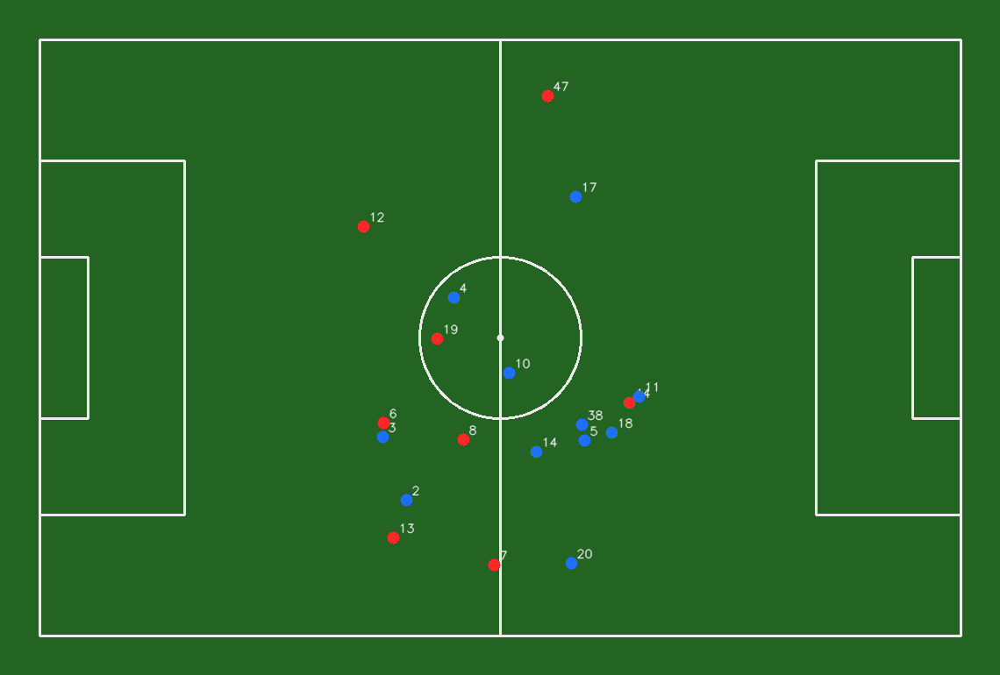


Projected outside the pitch: 0/19


In [15]:
import cv2
import numpy as np
from PIL import Image as PILImage
from IPython.display import display

# --------------------------------------------------
# 1. Verify required variables
# --------------------------------------------------

assert "tracking_data" in globals(), (
    "Load tracking_results1.pkl first."
)
assert "H_matrix" in globals(), (
    "Run the homography estimation cell first."
)

frame_index = 375
detections = tracking_data["frame_detections"][frame_index]
track_to_team = tracking_data["track_to_team"]

# Class mapping from the Phase 3 four-class detector.
# 0 = ball, 1 = goalkeeper, 2 = player, 3 = referee
PLAYER_CLASS_IDS = {1, 2}

# Match the reference dimensions used for H_matrix.
PITCH_LENGTH = 105.0
PITCH_WIDTH = 68.0

# --------------------------------------------------
# 2. Calculate each player's ground-contact point
# --------------------------------------------------

players = []

for det in detections:
    track_id = det.get("track_id")
    class_id = det.get("class_id")
    confidence = det.get("confidence")
    bbox = det.get("xyxy")

    # Skip incomplete or irrelevant detections.
    if track_id is None or class_id is None or bbox is None:
        continue

    if int(class_id) not in PLAYER_CLASS_IDS:
        continue

    if confidence is None or float(confidence) < 0.30:
        continue

    x1, y1, x2, y2 = map(float, bbox)

    # Approximate the player's contact point with the pitch.
    foot_x = (x1 + x2) / 2.0
    foot_y = y2

    players.append({
        "track_id": int(track_id),
        "class_id": int(class_id),
        "confidence": float(confidence),
        "team": track_to_team.get(int(track_id), -1),
        "pixel_x": foot_x,
        "pixel_y": foot_y,
    })

if not players:
    raise RuntimeError("No eligible player detections in frame 375.")

# --------------------------------------------------
# 3. Transform pixel positions into pitch coordinates
# --------------------------------------------------

image_points = np.array(
    [[p["pixel_x"], p["pixel_y"]] for p in players],
    dtype=np.float32
).reshape(-1, 1, 2)

pitch_points = cv2.perspectiveTransform(
    image_points, H_matrix
).reshape(-1, 2)

for player, (pitch_x, pitch_y) in zip(players, pitch_points):
    player["pitch_x"] = float(pitch_x)
    player["pitch_y"] = float(pitch_y)

    player["on_pitch"] = (
        0 <= pitch_x <= PITCH_LENGTH
        and 0 <= pitch_y <= PITCH_WIDTH
    )

# --------------------------------------------------
# 4. Print projected coordinates
# --------------------------------------------------

print(f"Frame: {frame_index}")
print(f"Eligible tracked players/goalkeepers: {len(players)}")

print(
    f"\n{'ID':>4} {'Class':>6} {'Team':>6} "
    f"{'Foot X':>9} {'Foot Y':>9} "
    f"{'Pitch X':>10} {'Pitch Y':>10} {'Status':>12}"
)

for p in players:
    class_name = "GK" if p["class_id"] == 1 else "Player"
    status = "IN PITCH" if p["on_pitch"] else "OUTSIDE"

    print(
        f"{p['track_id']:>4} "
        f"{class_name:>6} "
        f"{str(p['team']):>6} "
        f"{p['pixel_x']:>9.1f} "
        f"{p['pixel_y']:>9.1f} "
        f"{p['pitch_x']:>10.2f} "
        f"{p['pitch_y']:>10.2f} "
        f"{status:>12}"
    )

# --------------------------------------------------
# 5. Draw a top-down pitch and projected players
# --------------------------------------------------

SCALE = 10
MARGIN = 45

canvas_width = int(PITCH_LENGTH * SCALE + 2 * MARGIN)
canvas_height = int(PITCH_WIDTH * SCALE + 2 * MARGIN)

pitch_img = np.full(
    (canvas_height, canvas_width, 3),
    (35, 100, 35),
    dtype=np.uint8
)

def pitch_pixel(x, y):
    return (
        int(round(MARGIN + x * SCALE)),
        int(round(MARGIN + y * SCALE))
    )

white = (235, 235, 235)
thickness = 2

# Outer boundary.
cv2.rectangle(
    pitch_img,
    pitch_pixel(0, 0),
    pitch_pixel(PITCH_LENGTH, PITCH_WIDTH),
    white,
    thickness
)

# Halfway line.
cv2.line(
    pitch_img,
    pitch_pixel(PITCH_LENGTH / 2, 0),
    pitch_pixel(PITCH_LENGTH / 2, PITCH_WIDTH),
    white,
    thickness
)

# Centre circle and centre spot.
cv2.circle(
    pitch_img,
    pitch_pixel(PITCH_LENGTH / 2, PITCH_WIDTH / 2),
    int(round(9.15 * SCALE)),
    white,
    thickness
)
cv2.circle(
    pitch_img,
    pitch_pixel(PITCH_LENGTH / 2, PITCH_WIDTH / 2),
    4,
    white,
    -1
)

# Penalty and goal areas.
penalty_depth = 16.5
penalty_width = 40.32
goal_depth = 5.5
goal_width = 18.32

for x1, x2, area_width in [
    (0, penalty_depth, penalty_width),
    (PITCH_LENGTH - penalty_depth, PITCH_LENGTH, penalty_width),
    (0, goal_depth, goal_width),
    (PITCH_LENGTH - goal_depth, PITCH_LENGTH, goal_width),
]:
    y1 = (PITCH_WIDTH - area_width) / 2
    y2 = (PITCH_WIDTH + area_width) / 2

    cv2.rectangle(
        pitch_img,
        pitch_pixel(x1, y1),
        pitch_pixel(x2, y2),
        white,
        thickness
    )

# Projected team positions.
for p in players:
    x, y = p["pitch_x"], p["pitch_y"]

    # Only draw positions that fall within the reference pitch.
    if not p["on_pitch"]:
        continue

    # Team 0 = blue, team 1 = red, unknown = white.
    team_colors = {
        0: (255, 110, 30),
        1: (40, 40, 255),
    }
    color = team_colors.get(p["team"], (255, 255, 255))

    pixel = pitch_pixel(x, y)
    cv2.circle(pitch_img, pixel, 7, color, -1)
    cv2.putText(
        pitch_img,
        str(p["track_id"]),
        (pixel[0] + 6, pixel[1] - 6),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.45,
        white,
        1,
        cv2.LINE_AA
    )

print("\nTop-down projection (diagnostic only):")
print("Blue = team 0, red = team 1, white = unknown team")
print("Players projected outside the pitch are omitted from the drawing.")

display(PILImage.fromarray(cv2.cvtColor(pitch_img, cv2.COLOR_BGR2RGB)))

outside_count = sum(not p["on_pitch"] for p in players)
print(f"\nProjected outside the pitch: {outside_count}/{len(players)}")


Frame 150:
  Pitch-box confidence: 0.959
  Usable central landmarks: 6/6
  Landmark IDs: [14, 15, 16, 17, 31, 32]
  RANSAC inliers: 6/6
  Yellow = projected halfway line and centre circle


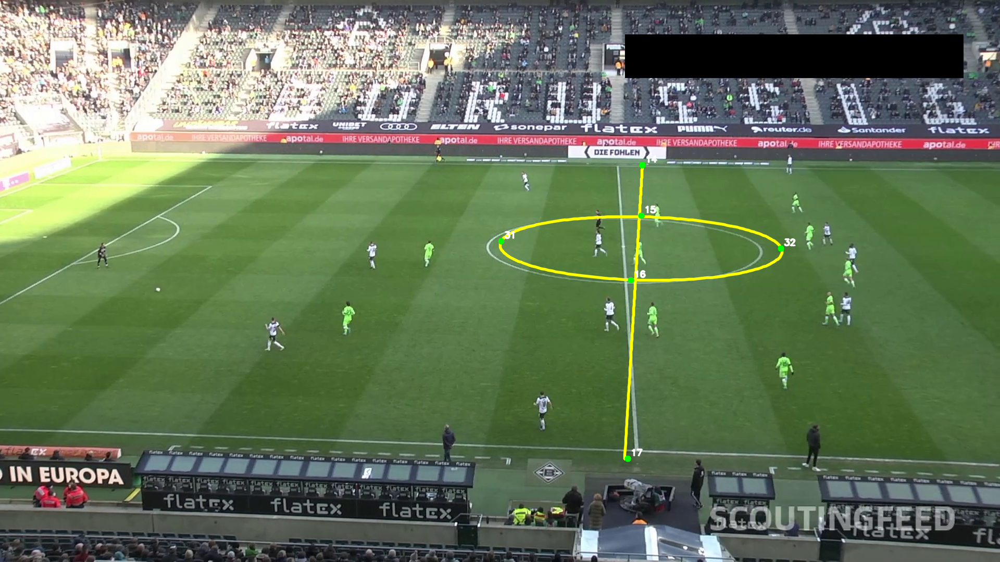


Frame 375:
  Pitch-box confidence: 0.951
  Usable central landmarks: 6/6
  Landmark IDs: [14, 15, 16, 17, 31, 32]
  RANSAC inliers: 6/6
  Yellow = projected halfway line and centre circle


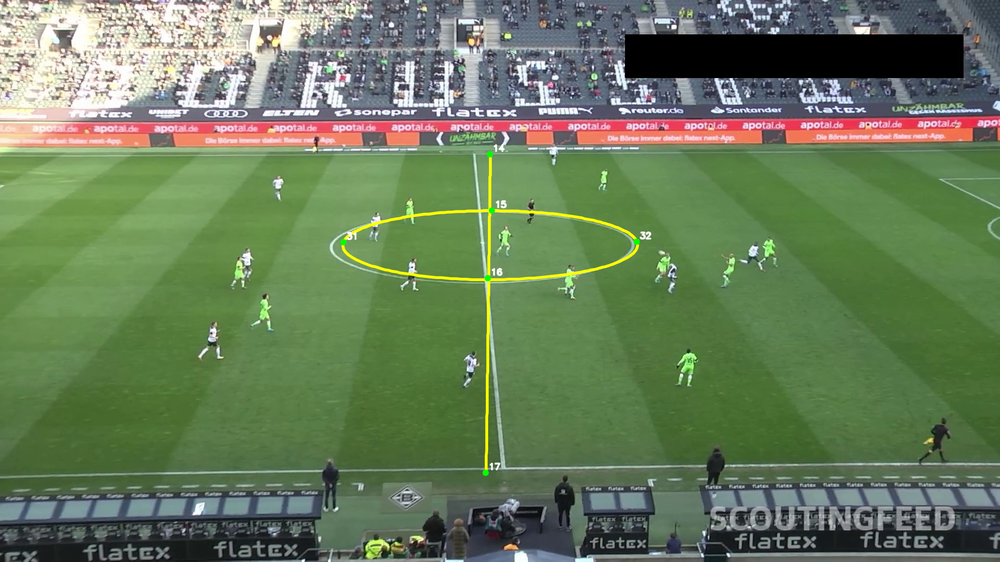


Frame 600:
  Pitch-box confidence: 0.959
  Usable central landmarks: 5/6
  Landmark IDs: [14, 15, 16, 17, 32]
  RANSAC inliers: 4/5


In [16]:
import cv2
import numpy as np
import torch
from PIL import Image as PILImage
from IPython.display import display

# Reuse model, VIDEO_PATH, and pitch_vertices from earlier cells.
assert "model" in globals(), "Load the trained model first."
assert "pitch_vertices" in globals(), "Run the pitch configuration cell first."

# Six central landmarks: IDs 14, 15, 16, 17, 31, 32.
selected_ids = [14, 15, 16, 17, 31, 32]
indices = np.array(selected_ids) - 1

LENGTH = 105.0
WIDTH = 68.0
RADIUS = 9.15

cap = cv2.VideoCapture(str(VIDEO_PATH))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

def draw_pitch_line(image, H_inverse, points_metres):
    """Project a pitch line back onto the video image."""
    H, W = image.shape[:2]

    pts = np.asarray(points_metres, dtype=np.float32).reshape(-1, 1, 2)
    img_pts = cv2.perspectiveTransform(pts, H_inverse).reshape(-1, 2)

    for a, b in zip(img_pts[:-1], img_pts[1:]):
        if not np.isfinite(a).all() or not np.isfinite(b).all():
            continue

        # Ignore unstable projections far beyond the image.
        if max(np.abs(a).max(), np.abs(b).max()) > 4 * max(W, H):
            continue

        p1 = tuple(np.round(a).astype(int))
        p2 = tuple(np.round(b).astype(int))

        visible, p1, p2 = cv2.clipLine((0, 0, W, H), p1, p2)
        if visible:
            cv2.line(image, p1, p2, (0, 255, 255), 3, cv2.LINE_AA)

def calibrate_frame(frame_index):
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_index)
    ok, frame = cap.read()

    if not ok:
        print(f"Frame {frame_index}: unable to read")
        return

    H_img, W_img = frame.shape[:2]

    # Same square-stretched inference used for frame 375.
    square = cv2.resize(frame, (640, 640))
    result = model.predict(
        source=square,
        imgsz=640,
        conf=0.05,
        max_det=1,
        device=0,
        verbose=False,
    )[0]

    if len(result.boxes) == 0 or result.keypoints is None:
        print(f"Frame {frame_index}: no pitch/keypoint detection")
        return

    pred = result.keypoints.data[0].cpu().numpy()
    image_points = pred[:, :2].copy()

    # Convert square-input coordinates back to video pixels.
    image_points[:, 0] *= W_img / 640
    image_points[:, 1] *= H_img / 640
    confidence = pred[:, 2]

    candidates = image_points[indices]
    candidate_conf = confidence[indices]

    # Reject low-confidence points and points on the image boundary.
    valid = (
        (candidate_conf >= 0.5)
        & (candidates[:, 0] > 1)
        & (candidates[:, 0] < W_img - 1)
        & (candidates[:, 1] > 1)
        & (candidates[:, 1] < H_img - 1)
    )

    source = candidates[valid].astype(np.float32)
    target = pitch_vertices[indices][valid].astype(np.float32)
    valid_ids = np.array(selected_ids)[valid]

    print(f"\nFrame {frame_index}:")
    print(f"  Pitch-box confidence: {result.boxes.conf[0].item():.3f}")
    print(f"  Usable central landmarks: {len(source)}/6")
    print(f"  Landmark IDs: {valid_ids.tolist()}")

    # Require five landmarks for this diagnostic.
    # Four points can mathematically define a homography, but leave little
    # opportunity to assess consistency.
    if len(source) < 5:
        print("  Skipped: insufficient landmarks for this diagnostic.")
        return

    H_matrix_frame, mask = cv2.findHomography(
        source,
        target,
        cv2.RANSAC,
        2.0,
    )

    if H_matrix_frame is None or mask is None:
        print("  Skipped: homography estimation failed.")
        return

    inliers = mask.ravel().astype(bool)
    inlier_count = int(inliers.sum())

    print(f"  RANSAC inliers: {inlier_count}/{len(source)}")

    if inlier_count < 5:
        print("  Warning: calibration is weak; inspect cautiously.")
        return

    H_inverse = np.linalg.inv(H_matrix_frame)
    overlay = frame.copy()

    # Project the halfway line.
    halfway = np.column_stack([
        np.full(150, LENGTH / 2, dtype=np.float32),
        np.linspace(0, WIDTH, 150, dtype=np.float32),
    ])
    draw_pitch_line(overlay, H_inverse, halfway)

    # Project the centre circle.
    angles = np.linspace(0, 2 * np.pi, 200, dtype=np.float32)
    circle = np.column_stack([
        LENGTH / 2 + RADIUS * np.cos(angles),
        WIDTH / 2 + RADIUS * np.sin(angles),
    ])
    draw_pitch_line(overlay, H_inverse, circle)

    # Draw used landmarks: green = inlier, red = outlier.
    for point_id, point, is_inlier in zip(valid_ids, source, inliers):
        x, y = np.round(point).astype(int)
        color = (0, 255, 0) if is_inlier else (0, 0, 255)
        cv2.circle(overlay, (x, y), 6, color, -1)
        cv2.putText(
            overlay, str(point_id), (x + 6, y - 6),
            cv2.FONT_HERSHEY_SIMPLEX, 0.55,
            (255, 255, 255), 2, cv2.LINE_AA,
        )

    print("  Yellow = projected halfway line and centre circle")
    display(PILImage.fromarray(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)))

# Test earlier, middle, and later portions of the video.
for idx in [150, 375, 600]:
    calibrate_frame(idx)

cap.release()

In [17]:
from pathlib import Path
import cv2
import numpy as np
import torch
import gc

# Verify that the earlier setup cells have run.
assert "model" in globals(), "Load your trained YOLO model first."
assert "pitch_vertices" in globals(), "Define the reference pitch first."
assert "VIDEO_PATH" in globals(), "Set VIDEO_PATH first."

VIDEO_PATH = Path(VIDEO_PATH)

# Use these six landmarks, whose projected alignment we inspected.
CENTRAL_IDS = [14, 15, 16, 17, 31, 32]
CENTRAL_IDX = np.array(CENTRAL_IDS) - 1

CONF_THRESHOLD = 0.50
RANSAC_THRESHOLD_METRES = 2.0

cap = cv2.VideoCapture(str(VIDEO_PATH))
if not cap.isOpened():
    raise RuntimeError(f"Could not open video: {VIDEO_PATH}")

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
video_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
video_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

# NaN means no trustworthy homography was produced for that frame.
homographies = np.full((total_frames, 3, 3), np.nan, dtype=np.float64)
valid_frames = np.zeros(total_frames, dtype=bool)
candidate_counts = np.zeros(total_frames, dtype=np.int16)
inlier_counts = np.zeros(total_frames, dtype=np.int16)
pitch_confidences = np.full(total_frames, np.nan)
median_errors_m = np.full(total_frames, np.nan)

target_all = np.asarray(pitch_vertices, dtype=np.float32)
assert target_all.shape == (32, 2), (
    f"Expected 32 reference vertices, got {target_all.shape}"
)

print(f"Video: {video_width} x {video_height}")
print(f"Frames to process: {total_frames}")
print("Starting per-frame calibration...")

for frame_idx in range(total_frames):
    ok, frame = cap.read()

    if not ok:
        print(f"Could not read frame {frame_idx}; stopping.")
        break

    # Match the square-stretched input used in our successful diagnostics.
    square = cv2.resize(frame, (640, 640), interpolation=cv2.INTER_LINEAR)

    result = model.predict(
        source=square,
        imgsz=640,
        conf=0.05,
        max_det=1,
        device=0,
        verbose=False,
    )[0]

    if len(result.boxes) == 0 or result.keypoints is None:
        del result
        continue

    pitch_confidences[frame_idx] = float(result.boxes.conf[0].item())

    points = result.keypoints.data[0].cpu().numpy()

    # Convert predicted positions back to original video pixels.
    points_original = points[:, :2].copy()
    points_original[:, 0] *= video_width / 640.0
    points_original[:, 1] *= video_height / 640.0

    selected_points = points_original[CENTRAL_IDX]
    selected_conf = points[CENTRAL_IDX, 2]

    inside = (
        (selected_points[:, 0] > 1)
        & (selected_points[:, 0] < video_width - 1)
        & (selected_points[:, 1] > 1)
        & (selected_points[:, 1] < video_height - 1)
    )

    usable = (selected_conf >= CONF_THRESHOLD) & inside
    candidate_counts[frame_idx] = int(usable.sum())

    # Require at least five of our six central landmarks.
    if usable.sum() < 5:
        del result
        continue

    source_points = selected_points[usable].astype(np.float32)
    target_points = target_all[CENTRAL_IDX][usable].astype(np.float32)

    H_frame, mask = cv2.findHomography(
        source_points,
        target_points,
        cv2.RANSAC,
        RANSAC_THRESHOLD_METRES,
    )

    del result

    if H_frame is None or mask is None:
        continue

    inliers = mask.ravel().astype(bool)
    n_inliers = int(inliers.sum())
    inlier_counts[frame_idx] = n_inliers

    # Require at least five consistent correspondences.
    if n_inliers < 5 or not np.isfinite(H_frame).all():
        continue

    projected = cv2.perspectiveTransform(
        source_points.reshape(-1, 1, 2),
        H_frame,
    ).reshape(-1, 2)

    errors = np.linalg.norm(projected - target_points, axis=1)
    median_error = float(np.median(errors[inliers]))

    if not np.isfinite(median_error):
        continue

    homographies[frame_idx] = H_frame
    median_errors_m[frame_idx] = median_error
    valid_frames[frame_idx] = True

    if (frame_idx + 1) % 50 == 0:
        print(
            f"Processed {frame_idx + 1}/{total_frames} frames | "
            f"accepted: {int(valid_frames[:frame_idx + 1].sum())}"
        )

cap.release()
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Save everything needed for later processing.
OUTPUT_DIR = Path("/kaggle/working/FootballVision/phase4_training")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_PATH = OUTPUT_DIR / "per_frame_homographies.npz"

np.savez_compressed(
    OUTPUT_PATH,
    homographies=homographies,
    valid_frames=valid_frames,
    candidate_counts=candidate_counts,
    inlier_counts=inlier_counts,
    pitch_confidences=pitch_confidences,
    median_errors_m=median_errors_m,
    central_ids=np.asarray(CENTRAL_IDS),
)

accepted = int(valid_frames.sum())
print("\nCalibration summary")
print(f"Frames processed: {frame_idx + 1 if total_frames else 0}")
print(f"Accepted calibrations: {accepted}/{total_frames}")
print(f"Rejected/unavailable: {total_frames - accepted}")
print(f"Saved calibration data to: {OUTPUT_PATH}")

print("\nFirst 20 accepted frame indices:")
print(np.flatnonzero(valid_frames)[:20].tolist())

print("\nFirst 20 rejected frame indices:")
print(np.flatnonzero(~valid_frames)[:20].tolist())

Video: 1920 x 1080
Frames to process: 750
Starting per-frame calibration...
Processed 50/750 frames | accepted: 50
Processed 100/750 frames | accepted: 100
Processed 150/750 frames | accepted: 150
Processed 200/750 frames | accepted: 200
Processed 250/750 frames | accepted: 250
Processed 300/750 frames | accepted: 300
Processed 350/750 frames | accepted: 350
Processed 400/750 frames | accepted: 400
Processed 450/750 frames | accepted: 450
Processed 750/750 frames | accepted: 547

Calibration summary
Frames processed: 750
Accepted calibrations: 547/750
Rejected/unavailable: 203
Saved calibration data to: /kaggle/working/FootballVision/phase4_training/per_frame_homographies.npz

First 20 accepted frame indices:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]

First 20 rejected frame indices:
[498, 499, 500, 501, 502, 503, 504, 505, 506, 507, 508, 509, 510, 511, 512, 513, 514, 515, 516, 517]


In [18]:
from pathlib import Path
import numpy as np

CALIBRATION_PATH = Path(
    "/kaggle/working/FootballVision/phase4_training/"
    "per_frame_homographies.npz"
)

assert CALIBRATION_PATH.exists(), (
    f"Calibration file not found: {CALIBRATION_PATH}"
)

data = np.load(CALIBRATION_PATH)

valid = data["valid_frames"].astype(bool)
candidates = data["candidate_counts"]
inliers = data["inlier_counts"]
errors = data["median_errors_m"]
box_conf = data["pitch_confidences"]

total = len(valid)

print(f"Total frames: {total}")
print(f"Accepted: {valid.sum()} ({100 * valid.mean():.1f}%)")
print(f"Rejected: {(~valid).sum()} ({100 * (~valid).mean():.1f}%)")

# --------------------------------------------------
# Find consecutive runs of accepted/rejected frames
# --------------------------------------------------

def find_runs(mask):
    """Return consecutive (start, end) frame ranges for True values."""
    mask = np.asarray(mask, dtype=bool)

    changes = np.diff(np.r_[False, mask, False].astype(int))
    starts = np.where(changes == 1)[0]
    ends = np.where(changes == -1)[0] - 1

    return list(zip(starts.tolist(), ends.tolist()))

print("\n--- Rejected frame intervals ---")
rejected_runs = find_runs(~valid)

for start, end in sorted(
    rejected_runs,
    key=lambda pair: pair[1] - pair[0],
    reverse=True
)[:15]:
    print(
        f"Frames {start}-{end}: "
        f"{end - start + 1} consecutive rejected frames"
    )

print("\n--- Accepted frame intervals ---")
accepted_runs = find_runs(valid)

for start, end in sorted(
    accepted_runs,
    key=lambda pair: pair[1] - pair[0],
    reverse=True
)[:10]:
    print(
        f"Frames {start}-{end}: "
        f"{end - start + 1} consecutive accepted frames"
    )

# --------------------------------------------------
# Diagnose why frames were rejected
# --------------------------------------------------

too_few_candidates = (~valid) & (candidates < 5)
candidate_but_rejected = (~valid) & (candidates >= 5)

print("\n--- Rejection diagnostics ---")
print(
    "Fewer than 5 usable landmarks:",
    int(too_few_candidates.sum())
)
print(
    "At least 5 landmarks, but calibration still rejected:",
    int(candidate_but_rejected.sum())
)

# --------------------------------------------------
# Inspect the fitting errors for accepted frames
# --------------------------------------------------

accepted_errors = errors[valid]
accepted_errors = accepted_errors[np.isfinite(accepted_errors)]

if len(accepted_errors):
    print("\n--- Accepted-frame fitting errors ---")
    print(f"Median: {np.median(accepted_errors):.3f} m")
    print(f"90th percentile: {np.percentile(accepted_errors, 90):.3f} m")
    print(f"Maximum: {np.max(accepted_errors):.3f} m")
    print(
        "Accepted frames with fitting error > 0.5 m:",
        int((accepted_errors > 0.5).sum())
    )

# --------------------------------------------------
# Summarize landmark availability over the video
# --------------------------------------------------

print("\n--- Every 50 frames ---")
for start in range(0, total, 50):
    end = min(start + 50, total)

    print(
        f"{start:03d}-{end - 1:03d}: "
        f"{int(valid[start:end].sum())}/{end-start} accepted; "
        f"mean usable landmarks="
        f"{np.mean(candidates[start:end]):.2f}"
    )

Total frames: 750
Accepted: 547 (72.9%)
Rejected: 203 (27.1%)

--- Rejected frame intervals ---
Frames 498-700: 203 consecutive rejected frames

--- Accepted frame intervals ---
Frames 0-497: 498 consecutive accepted frames
Frames 701-749: 49 consecutive accepted frames

--- Rejection diagnostics ---
Fewer than 5 usable landmarks: 0
At least 5 landmarks, but calibration still rejected: 203

--- Accepted-frame fitting errors ---
Median: 0.179 m
90th percentile: 0.418 m
Maximum: 0.715 m
Accepted frames with fitting error > 0.5 m: 21

--- Every 50 frames ---
000-049: 50/50 accepted; mean usable landmarks=6.00
050-099: 50/50 accepted; mean usable landmarks=6.00
100-149: 50/50 accepted; mean usable landmarks=6.00
150-199: 50/50 accepted; mean usable landmarks=6.00
200-249: 50/50 accepted; mean usable landmarks=6.00
250-299: 50/50 accepted; mean usable landmarks=6.00
300-349: 50/50 accepted; mean usable landmarks=6.00
350-399: 50/50 accepted; mean usable landmarks=6.00
400-449: 50/50 accepte

In [24]:
from pathlib import Path
import pickle
import cv2
import numpy as np
import gc
from IPython.display import FileLink, display

# ============================================================
# 1. INPUTS AND OUTPUT
# ============================================================

VIDEO_PATH = Path(
    "/kaggle/input/datasets/anishnagargoje/"
    "footballviddeo/08fd33_4.mp4"
)

TRACKING_PATH = Path(
    "/kaggle/input/datasets/anishnagargoje/"
    "footballviddeo/tracking_results1.pkl"
)

OUTPUT_DIR = Path(
    "/kaggle/working/FootballVision/phase4_training"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Prefer the calibration file containing four-point recoveries.
calibration_options = [
    OUTPUT_DIR / "per_frame_homographies_video.npz",
    OUTPUT_DIR / "per_frame_homographies.npz",
]

CALIBRATION_PATH = next(
    (p for p in calibration_options if p.exists()),
    None
)

assert VIDEO_PATH.exists(), f"Video not found: {VIDEO_PATH}"
assert TRACKING_PATH.exists(), f"Tracking data not found: {TRACKING_PATH}"
assert CALIBRATION_PATH is not None, (
    "No saved homography file was found. Run the calibration cell first."
)

OUTPUT_VIDEO = OUTPUT_DIR / "footballvision_broadcast_overlay.mp4"

# Keep the output at the original video's frame rate and resolution.
PLAYER_CONF = 0.30
BALL_CONF = 0.03
TRAIL_FRAMES = 10

# Reference pitch dimensions in metres.
PITCH_LENGTH = 105.0
PITCH_WIDTH = 68.0
CENTER_RADIUS = 9.15

# Colors are OpenCV BGR.
TEAM0_COLOR = (255, 140, 30)       # Blue
TEAM1_COLOR = (220, 40, 220)       # Magenta
GK0_COLOR = (255, 255, 0)          # Cyan
GK1_COLOR = (60, 255, 60)           # Lime green
GK_UNKNOWN_COLOR = (0, 165, 255)   # Orange
BALL_COLOR = (0, 240, 255)         # Yellow
REF_COLOR = (220, 220, 220)         # Grey
WHITE = (245, 245, 245)

# ============================================================
# 2. LOAD TRACKS AND CALIBRATIONS
# ============================================================

with open(TRACKING_PATH, "rb") as f:
    tracking_data = pickle.load(f)

calibration = np.load(CALIBRATION_PATH)

frame_detections = tracking_data["frame_detections"]
track_to_team = tracking_data["track_to_team"]

homographies = calibration["homographies"]
valid_frames = calibration["valid_frames"].astype(bool)

if "quality" in calibration.files:
    calibration_quality = calibration["quality"]
else:
    # Older calibration file: accepted=2, unavailable=0.
    calibration_quality = np.where(valid_frames, 2, 0).astype(np.uint8)

fps = float(tracking_data["metadata"].get("fps", 25.0))
num_frames = min(len(frame_detections), len(homographies))

print("Video frames:", num_frames)
print("FPS:", fps)
print("Calibration file:", CALIBRATION_PATH)
print("Frames with calibration:", int(valid_frames[:num_frames].sum()))

# Match track IDs to their team labels, regardless of key type.
def get_team(track_id):
    if track_id is None:
        return -1

    value = track_to_team.get(
        track_id,
        track_to_team.get(str(track_id), -1)
    )

    try:
        return int(value)
    except (TypeError, ValueError):
        return -1


def team_color(team):
    if team == 0:
        return TEAM0_COLOR
    if team == 1:
        return TEAM1_COLOR
    return WHITE


def goalkeeper_color(team):
    if team == 0:
        return GK0_COLOR
    if team == 1:
        return GK1_COLOR
    return GK_UNKNOWN_COLOR


def draw_labeled_box(image, bbox, color, label, thickness=2):
    """Draw a clipped detection box and a filled label."""
    h, w = image.shape[:2]
    x1, y1, x2, y2 = map(float, bbox)

    x1 = int(np.clip(round(x1), 0, w - 1))
    y1 = int(np.clip(round(y1), 0, h - 1))
    x2 = int(np.clip(round(x2), 0, w - 1))
    y2 = int(np.clip(round(y2), 0, h - 1))

    if x2 <= x1 or y2 <= y1:
        return

    cv2.rectangle(
        image, (x1, y1), (x2, y2), color, thickness, cv2.LINE_AA
    )

    font = cv2.FONT_HERSHEY_SIMPLEX
    font_scale = max(0.45, min(0.7, w / 2000))
    text_thickness = 1

    (tw, th), baseline = cv2.getTextSize(
        label, font, font_scale, text_thickness
    )

    label_top = max(0, y1 - th - baseline - 7)
    label_bottom = label_top + th + baseline + 7
    label_right = min(w - 1, x1 + tw + 10)

    cv2.rectangle(
        image,
        (x1, label_top),
        (label_right, label_bottom),
        color,
        -1,
    )
    cv2.putText(
        image,
        label,
        (x1 + 5, label_bottom - baseline - 3),
        font,
        font_scale,
        (0, 0, 0),
        text_thickness,
        cv2.LINE_AA,
    )


def project_point(bbox, class_id, H):
    """
    Ball: use its bounding-box centre.
    Players, goalkeepers, referees: use bottom-centre.
    Return pitch coordinates in metres, or None if outside the pitch.
    """
    x1, y1, x2, y2 = map(float, bbox)

    px = (x1 + x2) / 2
    py = (y1 + y2) / 2 if class_id == 0 else y2

    src = np.array([[[px, py]]], dtype=np.float32)
    result = cv2.perspectiveTransform(src, H)[0, 0]

    x, y = float(result[0]), float(result[1])

    if not np.isfinite([x, y]).all():
        return None

    if not (0 <= x <= PITCH_LENGTH and 0 <= y <= PITCH_WIDTH):
        return None

    return x, y


# ============================================================
# 3. CREATE A SEMI-TRANSPARENT TOP-DOWN PITCH OVERLAY
# ============================================================

cap = cv2.VideoCapture(str(VIDEO_PATH))
assert cap.isOpened(), f"Could not open video: {VIDEO_PATH}"

video_w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
video_h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

# Size chosen to resemble your reference: bottom-centre overlay.
map_w = min(
    int(video_w * 0.48),
    int(video_h * 0.52 * PITCH_LENGTH / PITCH_WIDTH)
)
map_h = int(map_w * PITCH_WIDTH / PITCH_LENGTH)

map_x = (video_w - map_w) // 2
map_y = video_h - map_h - max(15, int(video_h * 0.025))

# Inner pitch boundary.
pitch_pad = 12
pitch_scale = min(
    (map_w - 2 * pitch_pad) / PITCH_LENGTH,
    (map_h - 2 * pitch_pad) / PITCH_WIDTH,
)
field_w = int(round(PITCH_LENGTH * pitch_scale))
field_h = int(round(PITCH_WIDTH * pitch_scale))

field_left = (map_w - field_w) // 2
field_top = (map_h - field_h) // 2

map_background = np.full(
    (map_h, map_w, 3), (24, 36, 27), dtype=np.uint8
)

def local_pitch_px(x, y):
    return (
        int(round(field_left + x * pitch_scale)),
        int(round(field_top + y * pitch_scale)),
    )

# Grass stripes, with pitch x running left to right.
stripe_length = 7.0
x = 0.0
stripe_index = 0

while x < PITCH_LENGTH:
    x2 = min(x + stripe_length, PITCH_LENGTH)

    color = (
        (55, 126, 55)
        if stripe_index % 2 == 0
        else (45, 110, 47)
    )

    cv2.rectangle(
        map_background,
        local_pitch_px(x, 0),
        local_pitch_px(x2, PITCH_WIDTH),
        color,
        -1,
    )
    x = x2
    stripe_index += 1

line_color = (238, 242, 238)
line_width = 2

def pitch_line(x1, y1, x2, y2):
    cv2.line(
        map_background,
        local_pitch_px(x1, y1),
        local_pitch_px(x2, y2),
        line_color,
        line_width,
        cv2.LINE_AA,
    )

def pitch_rect(x1, y1, x2, y2):
    cv2.rectangle(
        map_background,
        local_pitch_px(x1, y1),
        local_pitch_px(x2, y2),
        line_color,
        line_width,
        cv2.LINE_AA,
    )

# Outer lines and halfway line.
pitch_rect(0, 0, PITCH_LENGTH, PITCH_WIDTH)
pitch_line(PITCH_LENGTH / 2, 0, PITCH_LENGTH / 2, PITCH_WIDTH)

# Centre circle and centre spot.
cv2.circle(
    map_background,
    local_pitch_px(PITCH_LENGTH / 2, PITCH_WIDTH / 2),
    int(round(CENTER_RADIUS * pitch_scale)),
    line_color,
    line_width,
    cv2.LINE_AA,
)

# Penalty boxes and goal areas.
penalty_depth = 16.5
penalty_width = 40.32
goal_depth = 5.5
goal_width = 18.32

for x1, x2, box_width in [
    (0, penalty_depth, penalty_width),
    (PITCH_LENGTH - penalty_depth, PITCH_LENGTH, penalty_width),
    (0, goal_depth, goal_width),
    (PITCH_LENGTH - goal_depth, PITCH_LENGTH, goal_width),
]:
    y1 = (PITCH_WIDTH - box_width) / 2
    y2 = (PITCH_WIDTH + box_width) / 2
    pitch_rect(x1, y1, x2, y2)

# Composite the map on each original frame using this opacity.
MAP_ALPHA = 0.68

def blend_map(frame):
    roi = frame[map_y:map_y + map_h, map_x:map_x + map_w]
    blended = cv2.addWeighted(
        roi, 1 - MAP_ALPHA,
        map_background, MAP_ALPHA,
        0
    )
    frame[map_y:map_y + map_h, map_x:map_x + map_w] = blended
    return frame


def map_pixel(x, y):
    px, py = local_pitch_px(x, y)
    return map_x + px, map_y + py


# ============================================================
# 4. OPEN THE MP4 WRITER
# ============================================================

fourcc = cv2.VideoWriter_fourcc(*"mp4v")
writer = cv2.VideoWriter(
    str(OUTPUT_VIDEO),
    fourcc,
    fps,
    (video_w, video_h),
)

if not writer.isOpened():
    cap.release()
    raise RuntimeError("Could not create the MP4 output.")

# Store a short trail for each tracked object.
histories = {}
TRAIL_LENGTH = 10


# ============================================================
# 5. RENDER THE ORIGINAL VIDEO + TACTICAL PITCH MAP
# ============================================================

for frame_idx in range(num_frames):
    ok, frame = cap.read()

    if not ok:
        print("Video ended at frame:", frame_idx)
        break

    detections = frame_detections[frame_idx]
    frame_calibrated = bool(valid_frames[frame_idx])
    frame_quality = int(calibration_quality[frame_idx])

    H = homographies[frame_idx] if frame_calibrated else None

    # We'll draw the original broadcast annotations first.
    # The translucent tactical map is layered over them afterwards.
    ball_candidate = None

    # Use the strongest ball detection for each frame, avoiding duplicates.
    for det in detections:
        if det.get("class_id") != 0:
            continue

        bbox = det.get("xyxy")
        conf = det.get("confidence")

        if bbox is None or len(bbox) != 4 or conf is None:
            continue

        conf = float(conf)

        if conf >= BALL_CONF:
            if ball_candidate is None or conf > ball_candidate["confidence"]:
                ball_candidate = {
                    "bbox": bbox,
                    "confidence": conf,
                    "track_id": det.get("track_id"),
                }

    # Draw outfield players, goalkeepers and referees.
    for det in detections:
        cls = det.get("class_id")
        track_id = det.get("track_id")
        bbox = det.get("xyxy")
        conf = det.get("confidence")

        if cls is None or bbox is None or len(bbox) != 4 or conf is None:
            continue

        cls = int(cls)
        conf = float(conf)

        # Ball is rendered separately below.
        if cls == 0:
            continue

        if cls not in (1, 2, 3):
            continue

        if conf < PLAYER_CONF:
            continue

        team = get_team(track_id)

        if cls == 1:
            color = goalkeeper_color(team)
            label = f"GK #{track_id}" if track_id is not None else "GOALKEEPER"
        elif cls == 2:
            color = team_color(team)
            label = f"#{track_id}" if track_id is not None else "PLAYER"
        else:
            color = REF_COLOR
            label = f"REF #{track_id}" if track_id is not None else "REFEREE"

        draw_labeled_box(frame, bbox, color, label)

    # Draw ball bbox and label on the camera view.
    if ball_candidate is not None:
        bbox = ball_candidate["bbox"]
        confidence = ball_candidate["confidence"]
        tid = ball_candidate["track_id"]

        draw_labeled_box(
            frame,
            bbox,
            BALL_COLOR,
            f"BALL {confidence:.2f}" if tid is None else f"BALL #{tid}",
            thickness=3,
        )

    # Add the semi-transparent reference pitch.
    blend_map(frame)

    # Render player dots only if the frame has a saved calibration.
    current_map_objects = []

    if frame_calibrated and H is not None:
        for det in detections:
            cls = det.get("class_id")
            track_id = det.get("track_id")
            bbox = det.get("xyxy")
            conf = det.get("confidence")

            if cls is None or bbox is None or len(bbox) != 4 or conf is None:
                continue

            cls = int(cls)
            conf = float(conf)

            if cls == 0:
                # Use the selected ball from above only.
                if ball_candidate is None:
                    continue
                if bbox != ball_candidate["bbox"] and not np.allclose(
                    np.asarray(bbox, dtype=float),
                    np.asarray(ball_candidate["bbox"], dtype=float)
                ):
                    continue

                # Keep ball threshold low due to its small size.
                if conf < BALL_CONF:
                    continue

                pos = project_point(bbox, cls, H)
                if pos is not None:
                    current_map_objects.append({
                        "key": "BALL",
                        "x": pos[0],
                        "y": pos[1],
                        "color": BALL_COLOR,
                        "kind": "ball",
                    })
                continue

            if cls not in (1, 2, 3):
                continue
            if conf < PLAYER_CONF:
                continue

            pos = project_point(bbox, cls, H)
            if pos is None:
                continue

            team = get_team(track_id)

            if cls == 1:
                color = goalkeeper_color(team)
                kind = "goalkeeper"
            elif cls == 2:
                color = team_color(team)
                kind = "player"
            else:
                color = REF_COLOR
                kind = "referee"

            key = (
                f"ref_{track_id}" if cls == 3
                else f"track_{track_id}"
            )

            current_map_objects.append({
                "key": key,
                "id": track_id,
                "x": pos[0],
                "y": pos[1],
                "color": color,
                "kind": kind,
            })

    # Update and prune recent trajectories.
    active_keys = set()

    for obj in current_map_objects:
        key = obj["key"]
        active_keys.add(key)

        histories.setdefault(key, []).append(
            (frame_idx, obj["x"], obj["y"], obj["color"])
        )

    for key in list(histories):
        histories[key] = [
            item for item in histories[key]
            if frame_idx - item[0] <= TRAIL_FRAMES
        ]

        if not histories[key]:
            del histories[key]

    # Draw trails on the mini-pitch, only connecting nearby frames.
    for history in histories.values():
        for a, b in zip(history[:-1], history[1:]):
            if b[0] - a[0] > 2:
                continue

            p1 = map_pixel(a[1], a[2])
            p2 = map_pixel(b[1], b[2])

            cv2.line(
                frame,
                p1,
                p2,
                b[3],
                2,
                cv2.LINE_AA,
            )

    # Draw the dots over the semi-transparent pitch.
    for obj in current_map_objects:
        px, py = map_pixel(obj["x"], obj["y"])
        color = obj["color"]

        if obj["kind"] == "ball":
            # Yellow ball with a dark outline.
            cv2.circle(frame, (px, py), 9, (0, 0, 0), -1, cv2.LINE_AA)
            cv2.circle(frame, (px, py), 6, BALL_COLOR, -1, cv2.LINE_AA)

        elif obj["kind"] == "goalkeeper":
            # Larger ring makes both keepers stand out from field players.
            cv2.circle(frame, (px, py), 9, WHITE, 2, cv2.LINE_AA)
            cv2.circle(frame, (px, py), 6, color, -1, cv2.LINE_AA)

        elif obj["kind"] == "referee":
            cv2.circle(frame, (px, py), 5, REF_COLOR, -1, cv2.LINE_AA)
        else:
            cv2.circle(frame, (px, py), 6, color, -1, cv2.LINE_AA)
            cv2.circle(frame, (px, py), 6, WHITE, 1, cv2.LINE_AA)

    # Header and calibration warning on the minimap.
    cv2.putText(
        frame,
        "REFERENCE PITCH  |  105 x 68 m",
        (map_x + 12, max(20, map_y - 10)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.55,
        WHITE,
        1,
        cv2.LINE_AA,
    )

    if not frame_calibrated:
        status = "PITCH CALIBRATION UNAVAILABLE - DOTS HIDDEN"
        status_color = (40, 40, 255)
    elif frame_quality == 1:
        status = "ESTIMATED CALIBRATION"
        status_color = (0, 180, 255)
    else:
        status = "PITCH CALIBRATION ACCEPTED"
        status_color = (60, 220, 80)

    cv2.rectangle(
        frame,
        (map_x + 8, map_y + map_h - 34),
        (map_x + map_w - 8, map_y + map_h - 8),
        (25, 30, 25),
        -1,
    )
    cv2.putText(
        frame,
        status,
        (map_x + 15, map_y + map_h - 16),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.43,
        status_color,
        1,
        cv2.LINE_AA,
    )

    # Frame clock.
    cv2.putText(
        frame,
        f"{frame_idx + 1}/{num_frames}  |  {frame_idx / fps:.2f}s",
        (24, 38),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.75,
        WHITE,
        2,
        cv2.LINE_AA,
    )

    writer.write(frame)

    if (frame_idx + 1) % 100 == 0:
        print(f"Rendered {frame_idx + 1}/{num_frames} frames")

cap.release()
writer.release()
gc.collect()

assert OUTPUT_VIDEO.exists() and OUTPUT_VIDEO.stat().st_size > 0, (
    "MP4 export failed."
)

print("\nVideo created successfully.")
print("Path:", OUTPUT_VIDEO)
print(f"File size: {OUTPUT_VIDEO.stat().st_size / (1024**2):.1f} MB")
print(f"Duration: {num_frames / fps:.1f} seconds")
print("\nClick below to download your video:")

display(FileLink(str(OUTPUT_VIDEO)))

Video frames: 750
FPS: 25.0
Calibration file: /kaggle/working/FootballVision/phase4_training/per_frame_homographies_video.npz
Frames with calibration: 547
Rendered 100/750 frames
Rendered 200/750 frames
Rendered 300/750 frames
Rendered 400/750 frames
Rendered 500/750 frames
Rendered 600/750 frames
Rendered 700/750 frames

Video created successfully.
Path: /kaggle/working/FootballVision/phase4_training/footballvision_broadcast_overlay.mp4
File size: 66.4 MB
Duration: 30.0 seconds

Click below to download your video:


/kaggle/working/FootballVision/phase4_training/footballvision_broadcast_overlay.mp4